## 1. Summary

This notebook investigates whether machine learning can support the Evaluation Committee in assessing agricultural mechanization prices using 3.505 historical records.

Three experiments were conducted:

- **Experiment 1:** Linear Regression, Ridge Regression, and Random Forest were evaluated on mechanization priced up to 50.000 EUR.
- **Experiment 2:** Ridge Regression was trained on the complete dataset, including higher-priced mechanization.
- **Experiment 3:** Ridge Regression was evaluated without the farmer's quoted price to examine the independence of reference price predictions.

Ridge Regression achieved the best regression performance in the first experiment. Training on the complete dataset resulted in fewer false acceptances, while removing the farmer's quoted price significantly reduced prediction accuracy.

The results show that machine learning has potential as a decision-support tool, but the current models are not sufficiently reliable for automatic price approval.

Further improvements should focus on reducing false acceptances and incorporating more detailed equipment characteristics and independent market price data.

## 2. Recap of the goal

The main goal of this project is to explore whether machine learning can help evaluate agricultural mechanization prices.

I will use the cleaned dataset from the EDA notebook, containing 3.505 records, to predict reference prices based on mechanization details and farmers' quoted prices.

The predicted reference prices will then be used to check whether quoted prices fall within a ±30% range.

I will evaluate the models using MAE, RMSE, and R², and compare their results with a simple baseline model.

## 3. Setup & data loading

I will import the libraries needed for modeling and load the cleaned dataset saved during EDA. This allows me to continue working with the prepared data without repeating the cleaning process.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

prices_analysis = pd.read_csv("https://raw.githubusercontent.com/milatovicdanka90-maker/dsb_capstone/refs/heads/main/Data/Processed/prices_analysis_clean.csv")

print("Dataset shape:", prices_analysis.shape)
prices_analysis.head()


Dataset shape: (3505, 17)


,No.,Supplier,Equipment / Item,Manufacturer / Brand,Model / Specifications,Evaluation Committee Reference Price (EUR),Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%),Evaluation Note,Record Frequency,Price Deviation (%),Original Deviation (%),Within 30%
0,1.0,Agromehanika doo,Potato ridger,Bomet,P475 3 rows,627.82,690.602,721.9930,816.166,595.04,595.040,-0.052212,NaN,1,-5.221242,-5.221242,True
1,1.0,Agromehanika doo,Potato planter,Bomet,S239/1 two-row,1427.63,1570.393,1641.7745,1855.919,1735.53,1570.393,0.215672,NaN,1,21.567213,21.567213,True
2,1.0,Agromehanika doo,Potato digger,Bomet,Z655 side-mounted,1621.54,1783.694,1864.7710,2108.002,1611.57,1611.570,-0.006148,NaN,1,-0.614848,-0.614848,True
3,1.0,Agromehanika doo,Rotary tiller,Farmers,180 cm,1443.61,1587.971,1660.1515,1876.693,1446.28,1446.280,0.001850,NaN,1,0.184953,0.184953,True
4,1.0,Agromehanika doo,Hay rake,FPM Deljanin,200 cm belt-type,855.00,940.500,983.2500,1111.500,979.33,979.330,0.145415,NaN,1,14.541520,14.541520,True


Before modeling, I will examine the number of mechanization items grouped by the `No.` column.

This will help me better understand the structure of the historical records and the volume of price assessments performed by the Evaluation Committee.

In [2]:
# Counting mechanization items by No.

grouped_data = prices_analysis.groupby("No.").agg({
    "Applicant Quoted Price (EUR)": "sum",
    "Supplier": "count"}).reset_index()

grouped_data.rename(columns={
    "Applicant Quoted Price (EUR)": "Total_Quoted_Price",
    "Supplier": "Items_per_group"}, inplace=True)

grouped_data.head()

,No.,Total_Quoted_Price,Items_per_group
0,1.0,29715.68,6
1,2.0,39994.89,5
2,3.0,38501.00,2
3,4.0,41170.00,8
4,5.0,10415.05,13


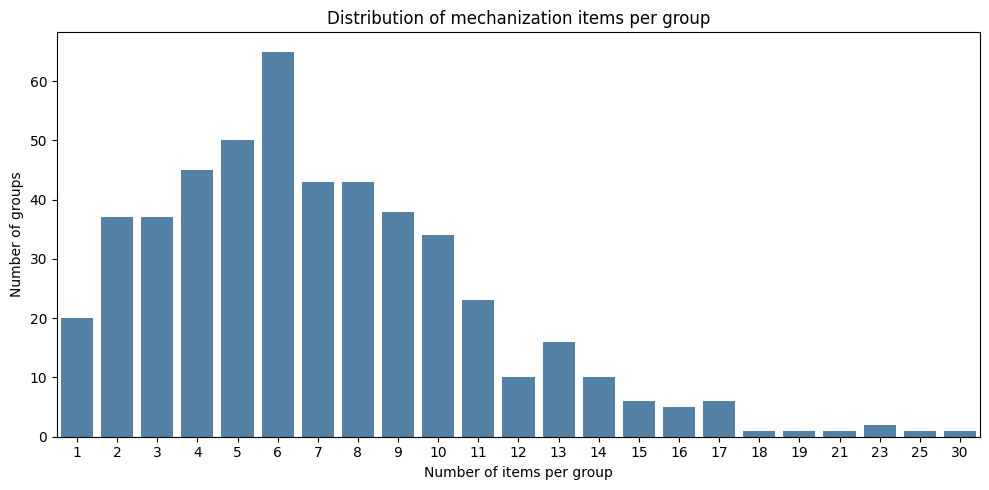

In [3]:
# Distribution of mechanization items per group

plt.figure(figsize=(10, 5))

sns.countplot(
    data=grouped_data,
    x="Items_per_group",
    color="steelblue")

plt.title("Distribution of mechanization items per group")
plt.xlabel("Number of items per group")
plt.ylabel("Number of groups")
plt.tight_layout()
plt.show()

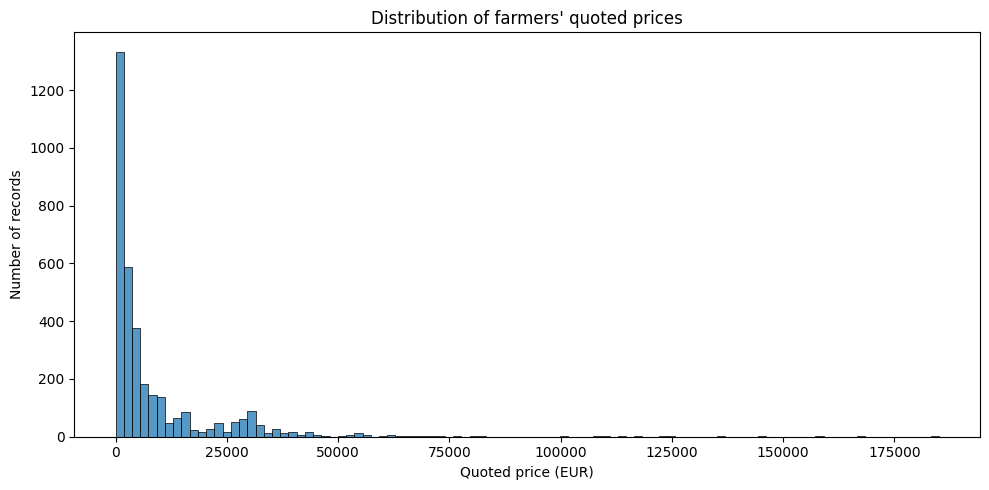

In [4]:
# Distribution of farmers' quoted mechanization prices

plt.figure(figsize=(10, 5))

sns.histplot(
    data=prices_analysis,
    x="Applicant Quoted Price (EUR)",
    bins=100)

plt.title("Distribution of farmers' quoted prices")
plt.xlabel("Quoted price (EUR)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

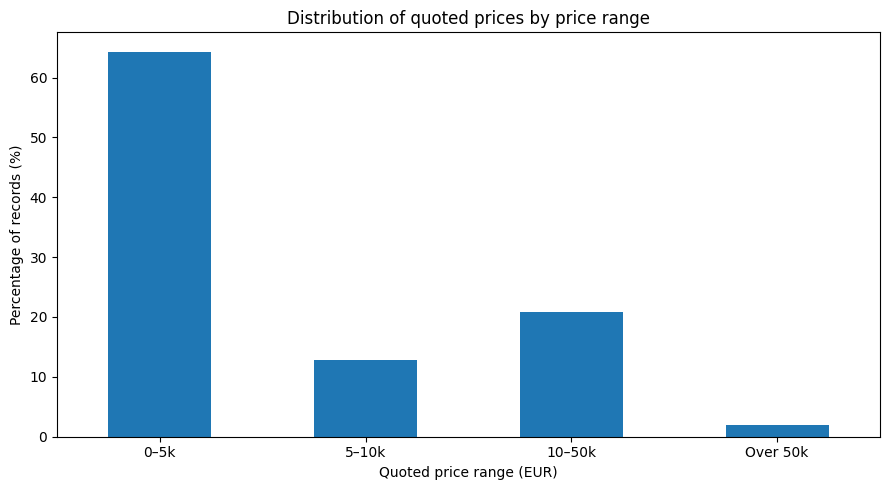

In [5]:
# Grouping quoted prices into four price ranges

price_ranges = pd.cut(
    prices_analysis["Applicant Quoted Price (EUR)"],
    bins=[0, 5000, 10000, 50000, float("inf")],
    labels=["0–5k", "5–10k", "10–50k", "Over 50k"])

price_percentages = price_ranges.value_counts(
    normalize=True).sort_index() * 100

plt.figure(figsize=(9, 5))

price_percentages.plot(kind="bar")

plt.title("Distribution of quoted prices by price range")
plt.xlabel("Quoted price range (EUR)")
plt.ylabel("Percentage of records (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Selecting the main price range for modeling

The price distribution shows that 98,0% of mechanization records have farmers' quoted prices up to 50.000 EUR.

I will first train and evaluate models on this price range. Later, I will compare their performance with models trained on the complete dataset, including higher-priced mechanization.

In [6]:
# Selecting mechanization with quoted prices up to 50.000 EUR

prices_under_50k = prices_analysis[
    prices_analysis["Applicant Quoted Price (EUR)"] <= 50000].copy()

print("Full dataset:", len(prices_analysis))
print("Selected dataset:", len(prices_under_50k))
print("Excluded records:", len(prices_analysis) - len(prices_under_50k))

Full dataset: 3505
Selected dataset: 3435
Excluded records: 70


## 4. Feature preparation

I will select four features to predict the reference price: equipment type, manufacturer, model specifications and the farmer's quoted price.

The target variable will be the Evaluation Committee Reference Price (EUR).

I will not use the columns calculated from the reference price as model features because they would cause data leakage.

In [7]:
# Selecting features and target for the first experiment

feature_columns = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications",
    "Applicant Quoted Price (EUR)"]

target_column = "Evaluation Committee Reference Price (EUR)"

X = prices_under_50k[feature_columns].copy()
y = prices_under_50k[target_column].copy()


# Filling missing categorical values

categorical_columns = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications"]

X[categorical_columns] = X[categorical_columns].fillna("Unknown")


print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3435, 4)
Target shape: (3435,)


In [8]:
X.isnull().sum()

,0
Equipment / Item,0
Manufacturer / Brand,0
Model / Specifications,0
Applicant Quoted Price (EUR),0


## 5. Train/test split

I will split the dataset into training (80%) and test (20%) sets using `train_test_split`.

The split will be performed randomly at the record level, without grouping by the `No.` column.

I will use `random_state=42` to make the results reproducible.

In [9]:
# Splitting the dataset into training and test sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 2748
Test records: 687


## 6. Baseline model

Before training machine learning models, I will create a simple baseline using the average reference price from the training data.

The baseline will predict the same average price for every record in the test set. This will help me evaluate whether the machine learning models perform better than a simple prediction.

In [10]:
# Calculating the average reference price from training data
baseline_price = y_train.mean()


# Using the average as a prediction for all test records
baseline_predictions = np.full(len(y_test), baseline_price)

print("Average reference price:", round(baseline_price, 2))
print("Number of predictions:", len(baseline_predictions))

Average reference price: 6778.43
Number of predictions: 687


In [11]:
# Calculating baseline error

from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", round(baseline_mae, 2))

Baseline MAE: 6867.39


The baseline model was evaluated on 687 test records containing mechanization with farmers' quoted prices up to 50.000 EUR.

The baseline predicts the same average reference price of 6.778,43 EUR for every test record.

The baseline MAE is 6.867,39 EUR, indicating that predicting a single average price results in substantial errors.

This result will be used as a benchmark for comparing the machine learning models in the first experiment.

## 7. Candidate models

Before training the models, I need to prepare four input features: three categorical features (equipment type, manufacturer and model specifications) and one numerical feature (the farmer's quoted price).

I will use OneHotEncoder to convert categorical features into numerical values and StandardScaler to scale the farmer's quoted price.

In [12]:
# Preparing categorical and numerical features

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications"]

numerical_features = ["Applicant Quoted Price (EUR)"]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numerical", StandardScaler(), numerical_features)])

### Linear Regression

I will use Linear Regression as my first machine learning model to predict reference prices.

I will combine the feature preparation and the model in a Pipeline, so the same transformations are applied during training and prediction.

In [13]:
# Training the Linear Regression model

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)])),
    ("model", LinearRegression())])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


I will use the trained Linear Regression model to predict reference prices for the test data.

These predictions will be compared with the actual reference prices to evaluate the model's performance.

In [14]:
# Predicting reference prices for test data

linear_predictions = linear_model.predict(X_test)

print("Number of predictions:", len(linear_predictions))
print("First five predictions:", linear_predictions[:5].round(2))

Number of predictions: 687
First five predictions: [4114.98  347.28   78.8   606.78 1489.43]


I will evaluate the Linear Regression model using MAE, RMSE, and R².

These metrics will help me understand how accurately the model predicts reference prices and how well it performs on the test data.

In [15]:
# Evaluating Linear Regression

from sklearn.metrics import mean_squared_error, r2_score

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))
print("Linear Regression R²:", round(linear_r2, 4))

Linear Regression MAE: 556.75
Linear Regression RMSE: 1770.56
Linear Regression R²: 0.9661


### Linear Regression – Findings

The Linear Regression model was evaluated on 687 test records with farmers' quoted prices up to 50.000 EUR.

The model achieved an MAE of 556,75 EUR, an RMSE of 1.770,56 EUR, and an R² of 0,9661.

These results are substantially better than the baseline MAE of 6.867,39 EUR.

However, the training MAE was only 40,36 EUR, compared to the test MAE of 556,75 EUR. This large difference suggests possible overfitting and indicates that the model performs less accurately on unseen data.

Ridge Regression and Random Forest will be evaluated to determine whether regularization or a different modeling approach can improve generalization.

### Ridge Regression

I will use Ridge Regression as my second model.

Ridge Regression is similar to Linear Regression, but it uses regularization to reduce the risk of overfitting.

I will use the same feature preparation and train/test split to compare both models fairly.

In [16]:
# Training the Ridge Regression model

from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)])),
    ("model", Ridge(alpha=1.0))])

ridge_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


I will use the Ridge Regression model to predict reference prices for the test data.

I will evaluate the predictions using the same metrics as Linear Regression: MAE, RMSE, and R².

In [17]:
# Predicting and evaluating Ridge Regression

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression MAE:", round(ridge_mae, 2))
print("Ridge Regression RMSE:", round(ridge_rmse, 2))
print("Ridge Regression R²:", round(ridge_r2, 4))

Ridge Regression MAE: 308.08
Ridge Regression RMSE: 791.98
Ridge Regression R²: 0.9932


The Ridge Regression model was evaluated on 687 test records with farmers' quoted prices up to 50.000 EUR.

The model achieved an MAE of 308,08 EUR, an RMSE of 791,98 EUR, and an R² of 0,9932.

Ridge Regression performed better than Linear Regression, reducing the test MAE from 556,75 EUR to 308,08 EUR.

The training MAE was 205,25 EUR, compared to the test MAE of 308,08 EUR. The smaller difference between training and test errors suggests better generalization than Linear Regression.

These results indicate that Ridge Regression is a promising model for predicting reference prices. However, its reliability for assessing price acceptability must also be evaluated using the ±30% threshold.

### Random Forest Regression

I will use Random Forest Regression as my third model.

Unlike Linear Regression and Ridge Regression, Random Forest can capture more complex relationships between mechanization characteristics and reference prices.

I will compare its performance on training and test data to check for overfitting.

In [18]:
# Training the Random Forest model

from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)])),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1))])

forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


I will evaluate the Random Forest model using MAE, RMSE, and R² on the test data.

I will also compare the training and test MAE to check whether the model is overfitting.

In [19]:
# Evaluating Random Forest

forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

forest_train_mae = mean_absolute_error(
    y_train, forest_model.predict(X_train))

print("Random Forest MAE:", round(forest_mae, 2))
print("Random Forest RMSE:", round(forest_rmse, 2))
print("Random Forest R²:", round(forest_r2, 4))

print("Random Forest Train MAE:", round(forest_train_mae, 2))

Random Forest MAE: 319.76
Random Forest RMSE: 892.17
Random Forest R²: 0.9914
Random Forest Train MAE: 328.17


The Random Forest model was evaluated on 687 test records with farmers' quoted prices up to 50.000 EUR.

The model achieved an MAE of 319,76 EUR, an RMSE of 892,17 EUR, and an R² of 0,9914.

The training MAE was 328,17 EUR, compared to the test MAE of 319,76 EUR. These similar values do not indicate obvious overfitting on this train/test split.

Random Forest performed substantially better than the baseline and Linear Regression models. However, Ridge Regression achieved slightly better results, with a lower MAE of 308,08 EUR.

Both Ridge Regression and Random Forest appear promising for predicting reference prices, but additional evaluation is needed to determine how reliably they support price acceptance decisions.

## 8. Evaluation & comparison

I will compare the baseline model, Linear Regression, Ridge Regression, and Random Forest to determine which model predicts reference prices most accurately.

I will use MAE, RMSE, and R² to compare their performance on the test data. Lower MAE and RMSE values and a higher R² indicate better results.

In [20]:
# Comparing model performance

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"],
    "MAE (EUR)": [
        baseline_mae,
        linear_mae,
        ridge_mae,
        forest_mae],
    "RMSE (EUR)": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        linear_rmse,
        ridge_rmse,
        forest_rmse],
    "R²": [
        r2_score(y_test, baseline_predictions),
        linear_r2,
        ridge_r2,
        forest_r2]})

comparison.round(2)

,Model,MAE (EUR),RMSE (EUR),R²
0,Baseline,6867.39,9612.38,-0.00
1,Linear Regression,556.75,1770.56,0.97
2,Ridge Regression,308.08,791.98,0.99
3,Random Forest,319.76,892.17,0.99


I will visualize the MAE values to compare the prediction errors of the four models.

A lower MAE means that the model's predictions are closer to the actual reference prices on average.

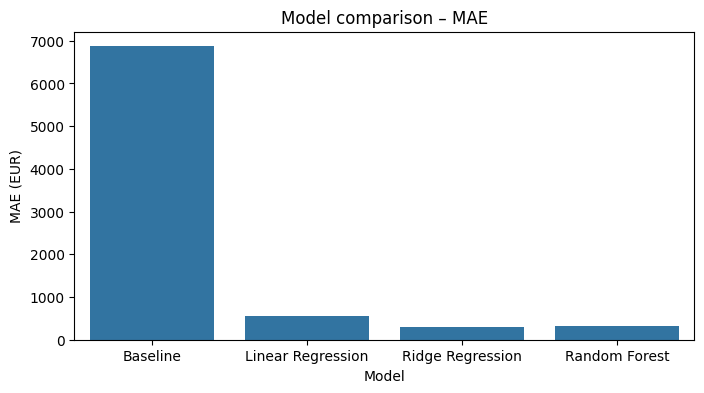

In [21]:
# Comparing model errors

plt.figure(figsize=(8, 4))

sns.barplot(data=comparison, x="Model", y="MAE (EUR)")

plt.title("Model comparison – MAE")
plt.ylabel("MAE (EUR)")
plt.xlabel("Model")
plt.show()

The models were compared using 687 test records with farmers' quoted prices up to 50.000 EUR.

All three machine learning models performed substantially better than the baseline, which had an MAE of 6.867,39 EUR.

Ridge Regression achieved the best overall regression performance, with the lowest MAE (308,08 EUR), lowest RMSE (791,98 EUR), and highest R² (0,9932).

Random Forest achieved similar results, with an MAE of 319,76 EUR and an R² of 0,9914. Linear Regression performed less accurately, with an MAE of 556,75 EUR.

Based on these results, Ridge Regression was selected for further analysis.

However, regression metrics alone are not sufficient to determine whether the model can reliably support price acceptance decisions. Therefore, I will also evaluate prediction errors across different price ranges and compare actual and predicted decisions using the ±30% threshold.

### Overfitting check

I will compare training and test MAE for Linear Regression, Ridge Regression, and Random Forest.

A much lower training error than test error may indicate overfitting.

In [22]:
# Comparing training and test errors

linear_train_mae = mean_absolute_error(
    y_train, linear_model.predict(X_train))

ridge_train_mae = mean_absolute_error(
    y_train, ridge_model.predict(X_train))

forest_train_mae = mean_absolute_error(
    y_train, forest_model.predict(X_train))

print("Linear Regression - Train MAE:", round(linear_train_mae, 2))
print("Linear Regression - Test MAE:", round(linear_mae, 2))

print("Ridge Regression - Train MAE:", round(ridge_train_mae, 2))
print("Ridge Regression - Test MAE:", round(ridge_mae, 2))

print("Random Forest - Train MAE:", round(forest_train_mae, 2))
print("Random Forest - Test MAE:", round(forest_mae, 2))

Linear Regression - Train MAE: 40.36
Linear Regression - Test MAE: 556.75
Ridge Regression - Train MAE: 205.25
Ridge Regression - Test MAE: 308.08
Random Forest - Train MAE: 328.17
Random Forest - Test MAE: 319.76


I compared training and test MAE to examine how well the models generalize to unseen data in the first experiment.

- **Linear Regression:** Training MAE was 40,36 EUR, while test MAE was 556,75 EUR. This large difference suggests possible overfitting.
- **Ridge Regression:** Training MAE was 205,25 EUR, while test MAE was 308,08 EUR. The smaller difference suggests better generalization than Linear Regression.
- **Random Forest:** Training MAE was 328,17 EUR, while test MAE was 319,76 EUR. The similar values do not indicate obvious overfitting on this train/test split.

Overall, Ridge Regression achieved the lowest test MAE, while Random Forest also showed relatively stable performance.

These findings are based on one train/test split, so they do not guarantee the same performance on new data.

## 9. Error analysis

I will analyze the prediction errors of Ridge Regression, which currently has the lowest MAE on the test data.

I will compare the actual reference prices with the predicted prices and calculate the error for each test record.

This will help me understand where the model makes larger prediction errors.

In [23]:
# Analyzing Ridge Regression prediction errors

error_analysis = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": ridge_predictions})

error_analysis["Error (EUR)"] = (
    error_analysis["Predicted Price"] - error_analysis["Actual Price"])

error_analysis["Absolute Error (EUR)"] = (
    error_analysis["Error (EUR)"].abs())

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR)
1744,4114.98,3723.72,-391.26,391.26
1668,1666.67,877.34,-789.33,789.33
946,78.74,91.55,12.81,12.81
3025,606.79,624.10,17.31,17.31
205,1489.45,1487.14,-2.31,2.31
1520,1232.21,1227.44,-4.77,4.77
2425,2394.00,2395.82,1.82,1.82
1490,3850.00,3946.50,96.50,96.50
562,26995.90,26992.56,-3.34,3.34
572,36555.00,37222.75,667.75,667.75


### Percentage error

Since mechanization prices vary significantly, I will also calculate the absolute percentage error for each prediction.

This will help me compare prediction accuracy across different price ranges.

In [24]:
# Calculating absolute percentage error

error_analysis["Percentage Error (%)"] = (
    error_analysis["Absolute Error (EUR)"]
    / error_analysis["Actual Price"] * 100)

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR),Percentage Error (%)
1744,4114.98,3723.72,-391.26,391.26,9.51
1668,1666.67,877.34,-789.33,789.33,47.36
946,78.74,91.55,12.81,12.81,16.27
3025,606.79,624.10,17.31,17.31,2.85
205,1489.45,1487.14,-2.31,2.31,0.16
1520,1232.21,1227.44,-4.77,4.77,0.39
2425,2394.00,2395.82,1.82,1.82,0.08
1490,3850.00,3946.50,96.50,96.50,2.51
562,26995.90,26992.56,-3.34,3.34,0.01
572,36555.00,37222.75,667.75,667.75,1.83


### Error analysis by price range

I will analyze prediction errors across different price ranges to understand whether the model performs equally well for lower-priced and higher-priced mechanization.

I will use the farmer's quoted price to define price categories, since this information is available when a new application is submitted.

In [25]:
# Adding farmers' quoted prices to error analysis

error_analysis["Quoted Price"] = X_test["Applicant Quoted Price (EUR)"]

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR),Percentage Error (%),Quoted Price
1744,4114.98,3723.72,-391.26,391.26,9.51,3900.00
1668,1666.67,877.34,-789.33,789.33,47.36,1100.00
946,78.74,91.55,12.81,12.81,16.27,77.42
3025,606.79,624.10,17.31,17.31,2.85,627.11
205,1489.45,1487.14,-2.31,2.31,0.16,1810.00
1520,1232.21,1227.44,-4.77,4.77,0.39,1363.63
2425,2394.00,2395.82,1.82,1.82,0.08,2200.00
1490,3850.00,3946.50,96.50,96.50,2.51,6300.00
562,26995.90,26992.56,-3.34,3.34,0.01,28525.00
572,36555.00,37222.75,667.75,667.75,1.83,39900.00


In [26]:
# Now I want to explore the distribution of quoted prices

error_analysis["Quoted Price"].describe().round(2)

,Quoted Price
count,687.00
mean,7089.10
std,10018.96
min,2.50
25%,1100.00
50%,2490.00
75%,7850.00
max,47400.00


I will divide the test data into two price categories based on the median quoted price: lower-priced and higher-priced mechanization.

This will help me compare prediction errors across different price ranges.

In [27]:
# Dividing quoted prices into two categories using the median

median_price = error_analysis["Quoted Price"].median()

error_analysis["Price Category"] = np.where(
    error_analysis["Quoted Price"] <= median_price,
    "Lower-priced",
    "Higher-priced")

print("Median quoted price:", round(median_price, 2))
print(error_analysis["Price Category"].value_counts())

Median quoted price: 2490.0
Price Category
Lower-priced     344
Higher-priced    343
Name: count, dtype: int64


### Prediction errors by price category

The test data was divided into two price categories based on the median quoted price calculated from the current test set.

I will compare the average absolute error in EUR and the average percentage error for both groups to see whether Ridge Regression performs differently across price ranges.

In [28]:
# Comparing prediction errors by price category

category_errors = error_analysis.groupby("Price Category")[
    ["Absolute Error (EUR)", "Percentage Error (%)"]].mean()

category_errors.round(2)

,Absolute Error (EUR),Percentage Error (%)
Price Category,,
Higher-priced,515.57,5.84
Lower-priced,101.20,39.78


### Error analysis by price category – findings

The test records were divided into two categories using the median farmer's quoted price of 2.490 EUR.

For lower-priced mechanization (344 records), Ridge Regression achieved an average absolute error of 101,20 EUR and an average absolute percentage error of 39,78%.

For higher-priced mechanization (343 records), the average absolute error was 515,57 EUR, while the average absolute percentage error was 5,84%.

These results show that lower-priced mechanization has smaller errors in EUR but much higher percentage errors.

This is important because even relatively small prediction errors can represent large percentage deviations for low-priced equipment.

Therefore, overall regression metrics should be considered together with percentage errors and the accuracy of price acceptance decisions.

### Large prediction errors

I will check how many predictions have an absolute percentage error greater than 30% in each price category.

This will help me identify where the model makes large prediction errors.

In [29]:
# Identifing prediction errors greater than 30%

error_analysis["Large Error"] = np.where(
    error_analysis["Percentage Error (%)"] > 30, 1, 0)

error_analysis.groupby("Price Category")["Large Error"].agg(["sum", "count"])

,sum,count
Price Category,,
Higher-priced,12,343
Lower-priced,43,344


In the first experiment, Ridge Regression produced prediction errors greater than 30% for 55 out of 687 test records (8,01%).

Among lower-priced mechanization (up to 2.490 EUR), 43 out of 344 records (12,50%) had prediction errors above 30%.

Among higher-priced mechanization (above 2.490 EUR), 12 out of 343 records (3,50%) had prediction errors above 30%.

These results indicate that large percentage prediction errors are more frequent among lower-priced mechanization.

This finding is important for identifying price categories where additional manual verification may be needed.

However, prediction errors greater than 30% should not be confused with incorrect price acceptance decisions under the ±30% rule.

### Price deviation analysis

I will compare the farmer's quoted price with both the actual and predicted reference prices.

This will help me evaluate whether Ridge Regression can correctly identify quoted prices that fall within the ±30% range.

In [30]:
# Calculating actual and predicted price deviations

error_analysis["Actual Deviation (%)"] = (
    (error_analysis["Quoted Price"] - error_analysis["Actual Price"])
    / error_analysis["Actual Price"] * 100)

error_analysis["Predicted Deviation (%)"] = (
    (error_analysis["Quoted Price"] - error_analysis["Predicted Price"])
    / error_analysis["Predicted Price"] * 100)

error_analysis[[
    "Quoted Price",
    "Actual Price",
    "Predicted Price",
    "Actual Deviation (%)",
    "Predicted Deviation (%)"]].head(10).round(2)

,Quoted Price,Actual Price,Predicted Price,Actual Deviation (%),Predicted Deviation (%)
1744,3900.00,4114.98,3723.72,-5.22,4.73
1668,1100.00,1666.67,877.34,-34.00,25.38
946,77.42,78.74,91.55,-1.68,-15.43
3025,627.11,606.79,624.10,3.35,0.48
205,1810.00,1489.45,1487.14,21.52,21.71
1520,1363.63,1232.21,1227.44,10.67,11.10
2425,2200.00,2394.00,2395.82,-8.10,-8.17
1490,6300.00,3850.00,3946.50,63.64,59.64
562,28525.00,26995.90,26992.56,5.66,5.68
572,39900.00,36555.00,37222.75,9.15,7.19


### Price deviation classification

I will classify quoted prices as within or outside the ±30% range using both actual and predicted reference prices.

I will then compare the two classifications to evaluate whether the model correctly identifies price deviations.

In [31]:
# Classifying prices using the 30% threshold

error_analysis["Actual Within 30%"] = (
    error_analysis["Actual Deviation (%)"].abs() <= 30)

error_analysis["Predicted Within 30%"] = (
    (error_analysis["Predicted Price"] > 0) &
    (error_analysis["Predicted Deviation (%)"].abs() <= 30))

pd.crosstab(
    error_analysis["Actual Within 30%"],
    error_analysis["Predicted Within 30%"])


Predicted Within 30%,False,True
Actual Within 30%,,
False,71,63
True,24,529


In the first experiment, Ridge Regression was evaluated on 687 test records using the ±30% price deviation threshold.

The model correctly classified 600 out of 687 records (87,34%).

However, 63 prices that were actually outside the acceptable range were incorrectly classified as acceptable (false acceptances), while 24 acceptable prices were incorrectly rejected (false rejections).

Out of 134 actually unacceptable prices, 63 (47,01%) were incorrectly accepted by the model.

These results show that strong regression performance does not necessarily lead to reliable price acceptance decisions.

The high number of false acceptances is a significant limitation. Therefore, the model should support the Evaluation Committee rather than automatically approve mechanization prices.

In [32]:
# Checking for invalid predicted prices

invalid_prices = (error_analysis["Predicted Price"] <= 0).sum()

print("Invalid predicted prices:", invalid_prices)

Invalid predicted prices: 0


In the first experiment, Ridge Regression produced no negative reference price predictions among the 687 test records.

This is a positive result because reference prices cannot be negative.

However, the absence of negative predictions does not guarantee that all predicted prices are accurate or suitable for automatic price acceptance decisions.

Additional evaluation of prediction errors and false acceptances remains necessary.

## Experiment 2 – modeling the complete dataset

In this experiment, I will include all 3.505 mechanization records.

To ensure a fair comparison with the first experiment, I will keep the same test records for mechanization priced up to 50.000 EUR.

I will also split the 70 higher-priced records into training and test sets, allowing me to evaluate model performance on this smaller price category separately.

The results will help determine whether including higher-priced mechanization improves prediction performance.

In [33]:
# Selecting mechanization priced above 50.000 EUR

prices_over_50k = prices_analysis[
    prices_analysis["Applicant Quoted Price (EUR)"] > 50000].copy()

X_high = prices_over_50k[feature_columns].copy()
y_high = prices_over_50k[target_column].copy()

# Filling missing categorical values
X_high[categorical_columns] = X_high[categorical_columns].fillna("Unknown")

# Splitting higher-priced records
X_high_train, X_high_test, y_high_train, y_high_test = train_test_split(
    X_high,
    y_high,
    test_size=0.2,
    random_state=42)

print("Higher-priced training records:", len(X_high_train))
print("Higher-priced test records:", len(X_high_test))

Higher-priced training records: 56
Higher-priced test records: 14


In [34]:
# Combining training and test data for the complete dataset

X_train_full = pd.concat([X_train, X_high_train])
X_test_full = pd.concat([X_test, X_high_test])

y_train_full = pd.concat([y_train, y_high_train])
y_test_full = pd.concat([y_test, y_high_test])

print("Full training records:", len(X_train_full))
print("Full test records:", len(X_test_full))
print("Total records:", len(X_train_full) + len(X_test_full))

Full training records: 2804
Full test records: 701
Total records: 3505


In [35]:
# Training Ridge Regression on the complete dataset

# Separate preprocessor for the second experiment
preprocessor_full = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numerical", StandardScaler(), numerical_features)])

# Creating the Ridge model
ridge_model_full = Pipeline([
    ("preprocessor", preprocessor_full),
    ("regressor", Ridge(alpha=1.0))])

# Training the model
ridge_model_full.fit(X_train_full, y_train_full)

# Predicting reference prices
ridge_predictions_full = ridge_model_full.predict(X_test_full)

# Evaluating the model
ridge_mae_full = mean_absolute_error(
    y_test_full, ridge_predictions_full)

ridge_rmse_full = np.sqrt(
    mean_squared_error(y_test_full, ridge_predictions_full))

ridge_r2_full = r2_score(
    y_test_full, ridge_predictions_full)

# Printing the results
print("Ridge Full - MAE:", round(ridge_mae_full, 2))
print("Ridge Full - RMSE:", round(ridge_rmse_full, 2))
print("Ridge Full - R²:", round(ridge_r2_full, 4))

Ridge Full - MAE: 426.98
Ridge Full - RMSE: 1380.89
Ridge Full - R²: 0.9926


In the second experiment, Ridge Regression was trained on 2.804 records from the complete dataset, including mechanization with quoted prices above 50.000 EUR.

The model was evaluated on 701 test records and achieved an MAE of 426,98 EUR, an RMSE of 1.380,89 EUR, and an R² of 0,9926.

These results indicate strong overall regression performance.

However, the test set includes both lower-priced and higher-priced mechanization. Therefore, these metrics should not be directly compared with the first experiment, which was evaluated on 687 records priced up to 50.000 EUR.

A separate comparison on the same 687 test records is needed to determine whether including higher-priced mechanization improves model performance.

In [36]:
# Comparing Ridge models on the same 687 test records

# Predictions from the model trained on all records
ridge_full_on_98 = ridge_model_full.predict(X_test)

# MAE for both models on the same test records
mae_98 = mean_absolute_error(y_test, ridge_predictions)

mae_100 = mean_absolute_error(y_test, ridge_full_on_98)

# RMSE for both models
rmse_98 = np.sqrt(
    mean_squared_error(y_test, ridge_predictions))

rmse_100 = np.sqrt(
    mean_squared_error(y_test, ridge_full_on_98))

# R2 for both models
r2_98 = r2_score(y_test, ridge_predictions)
r2_100 = r2_score(y_test, ridge_full_on_98)

# Comparing results
comparison = pd.DataFrame({
    "Model": ["Ridge 98%", "Ridge 100%"],
    "MAE (EUR)": [mae_98, mae_100],
    "RMSE (EUR)": [rmse_98, rmse_100],
    "R2": [r2_98, r2_100]})

comparison.round(2)

,Model,MAE (EUR),RMSE (EUR),R2
0,Ridge 98%,308.08,791.98,0.99
1,Ridge 100%,322.46,816.04,0.99


To ensure a fair comparison, both Ridge models were evaluated on the same 687 test records with farmers' quoted prices up to 50.000 EUR.

The Ridge model trained on 98% of the dataset achieved an MAE of 308,08 EUR and an RMSE of 791,98 EUR.

The Ridge model trained on the complete dataset achieved an MAE of 322,46 EUR and an RMSE of 816,04 EUR on these same test records.

The model trained on 98% of the data performed slightly better in predicting reference prices within this price range.

However, the difference in MAE was only 14,38 EUR. This suggests that including higher-priced mechanization in training did not substantially change prediction accuracy for lower-priced items.

Regression metrics alone are not sufficient to select the better model. The models must also be compared based on incorrect price acceptance decisions under the ±30% threshold.

In [37]:
# Evaluating Ridge 100% on higher-priced mechanization

ridge_high_predictions = ridge_model_full.predict(X_high_test)

high_mae = mean_absolute_error(y_high_test, ridge_high_predictions)

high_rmse = np.sqrt(mean_squared_error(y_high_test, ridge_high_predictions))

high_r2 = r2_score(y_high_test, ridge_high_predictions)

print("Higher-priced test records:", len(y_high_test))
print("Higher-priced MAE:", round(high_mae, 2))
print("Higher-priced RMSE:", round(high_rmse, 2))
print("Higher-priced R²:", round(high_r2, 4))

Higher-priced test records: 14
Higher-priced MAE: 5556.4
Higher-priced RMSE: 7924.72
Higher-priced R²: 0.9707


In [38]:
# Percentage prediction errors for higher-priced mechanization

high_percentage_errors = (
    np.abs(y_high_test - ridge_high_predictions)
    / y_high_test) * 100

print("Higher-priced mean absolute percentage error:",
    round(high_percentage_errors.mean(), 2), "%")

Higher-priced mean absolute percentage error: 6.1 %


The Ridge model trained on the complete dataset was evaluated separately on 14 test records with farmers' quoted prices above 50.000 EUR.

The model achieved an MAE of 5.556,40 EUR, an RMSE of 7.924,72 EUR, and an R² of 0,9707.

Although the absolute prediction errors were relatively large, the mean absolute percentage error was 6,10%. This indicates that the prediction errors were smaller relative to the actual reference prices.

These results suggest that the model may also be useful for higher-priced mechanization.

However, the test sample contains only 14 records, so these findings are preliminary and cannot establish reliable performance across all higher-priced equipment.

In [39]:
# Comparing price acceptance decisions on the same test records

quoted_prices = X_test["Applicant Quoted Price (EUR)"]

# Actual decisions based on Committee reference prices
actual_within_30 = (
    np.abs(quoted_prices - y_test) / y_test <= 0.30)

# Predicted decisions - Ridge trained on 98% of records
ridge_98_within_30 = (
    np.abs(quoted_prices - ridge_predictions) / ridge_predictions <= 0.30)

# Predicted decisions - Ridge trained on 100% of records
ridge_100_within_30 = (
    np.abs(quoted_prices - ridge_full_on_98) / ridge_full_on_98 <= 0.30)

# Counting incorrect decisions
results = pd.DataFrame({
    "Model": ["Ridge 98%", "Ridge 100%"],
    "False Acceptances": [
        ((~actual_within_30) & ridge_98_within_30).sum(),
        ((~actual_within_30) & ridge_100_within_30).sum()],
    "False Rejections": [
        (actual_within_30 & (~ridge_98_within_30)).sum(),
        (actual_within_30 & (~ridge_100_within_30)).sum()]})

results

,Model,False Acceptances,False Rejections
0,Ridge 98%,63,24
1,Ridge 100%,53,32


Both Ridge models were evaluated on the same 687 test records with farmers' quoted prices up to 50.000 EUR, using the ±30% price deviation threshold.

The Ridge model trained on 98% of the dataset produced 63 false acceptances and 24 false rejections.

The Ridge model trained on the complete dataset produced 53 false acceptances and 32 false rejections.

Although Ridge 98% achieved a slightly lower MAE, Ridge 100% incorrectly accepted 10 fewer unacceptable prices.

However, Ridge 100% also incorrectly rejected 8 more acceptable prices.

This shows that lower prediction error does not necessarily result in better price acceptance decisions.

Since false acceptances represent an important risk in price evaluation, Ridge 100% may be more suitable for further investigation as a decision-support model.

Nevertheless, both models still produce a substantial number of incorrect decisions, and neither should be used for fully automatic price approval based on these results alone.

In [40]:
# Checking 30% acceptance decisions for higher-priced mechanization

quoted_high = X_high_test["Applicant Quoted Price (EUR)"]

# Actual decisions
actual_high_within_30 = (
    np.abs(quoted_high - y_high_test) / y_high_test <= 0.30)

# Predicted decisions - Ridge trained on all records
predicted_high_within_30 = (
    np.abs(quoted_high - ridge_high_predictions)
    / ridge_high_predictions <= 0.30)

# Counting incorrect decisions
high_false_acceptances = (
    (~actual_high_within_30) & predicted_high_within_30).sum()

high_false_rejections = (
    actual_high_within_30 & (~predicted_high_within_30)).sum()

print("Higher-priced test records:", len(y_high_test))
print("False Acceptances:", high_false_acceptances)
print("False Rejections:", high_false_rejections)

Higher-priced test records: 14
False Acceptances: 0
False Rejections: 0


The Ridge model trained on the complete dataset was evaluated using the ±30% threshold on 14 higher-priced test records.

The model produced 0 false acceptances and 0 false rejections, correctly classifying all 14 test records.

This is an encouraging result and suggests that the model may also support price evaluation for higher-priced mechanization.

However, the sample is very small, and these results do not guarantee reliable performance on new higher-priced equipment.

Therefore, additional validation is needed before considering automated decisions for this price category.

## Experiment 3 – Ridge regression without the farmer's quoted price

In the previous experiments, the farmer's quoted price was included as one of the input features.

However, the Evaluation Committee aims to establish a reasonable reference price independently of the price proposed by the farmer.

To investigate whether the model can estimate reference prices without relying on the farmer's offer, I will train Ridge Regression using only three features:

- Equipment / Item
- Manufacturer / Brand
- Model / Specifications

The model will be trained and evaluated using the same records as Experiment 2.

I will compare prediction errors and price acceptance decisions to assess whether excluding the farmer's quoted price provides a more suitable approach for the project's objective.

In [41]:
# Preparing data without the farmer's quoted price

features_3 = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications"]

# Using the same training and test records as Experiment 2
X_train_3 = X_train_full[features_3].copy()
X_test_3 = X_test_full[features_3].copy()

# Checking the dimensions
print("Training records:", X_train_3.shape)
print("Test records:", X_test_3.shape)

Training records: (2804, 3)
Test records: (701, 3)


In [42]:
# Experiment 3 - Ridge Regression without quoted price

# Preparing categorical features
preprocessor_3 = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), features_3)])

# Creating the Ridge model
ridge_model_3 = Pipeline([
    ("preprocessor", preprocessor_3),
    ("model", Ridge(alpha=1.0))])

# Training the model
ridge_model_3.fit(X_train_3, y_train_full)

# Predicting reference prices
ridge_predictions_3 = ridge_model_3.predict(X_test_3)

# Evaluating the model
ridge_mae_3 = mean_absolute_error(
    y_test_full, ridge_predictions_3)

ridge_rmse_3 = np.sqrt(
    mean_squared_error(y_test_full, ridge_predictions_3))

ridge_r2_3 = r2_score(
    y_test_full, ridge_predictions_3)

print("Ridge 3 Features - MAE:", round(ridge_mae_3, 2))
print("Ridge 3 Features - RMSE:", round(ridge_rmse_3, 2))
print("Ridge 3 Features - R²:", round(ridge_r2_3, 4))

Ridge 3 Features - MAE: 1709.72
Ridge 3 Features - RMSE: 5956.13
Ridge 3 Features - R²: 0.8631


In [43]:
# Checking invalid reference price predictions in Experiment 3

invalid_predictions_3 = (ridge_predictions_3 <= 0).sum()

print("Invalid predicted prices:", invalid_predictions_3)

Invalid predicted prices: 9


In [44]:
# Checking price acceptance decisions for Ridge with 3 features

# Farmer's quoted prices
quoted_prices_3 = X_test_full[
    "Applicant Quoted Price (EUR)"].to_numpy()

# Actual reference prices
actual_prices_3 = y_test_full.to_numpy()

# Checking valid predicted reference prices
valid_predictions_3 = ridge_predictions_3 > 0

# Actual price acceptance decisions
actual_within_30_3 = (
    np.abs(quoted_prices_3 - actual_prices_3)
    / actual_prices_3 <= 0.30)

# Predicted decisions for valid reference prices only
predicted_within_30_3 = np.zeros(
    len(ridge_predictions_3), dtype=bool)

predicted_within_30_3[valid_predictions_3] = (
    np.abs(
        quoted_prices_3[valid_predictions_3]
        - ridge_predictions_3[valid_predictions_3])
    / ridge_predictions_3[valid_predictions_3] <= 0.30)

# Counting incorrect decisions among valid predictions
false_acceptances_3 = (
    valid_predictions_3
    & ~actual_within_30_3
    & predicted_within_30_3).sum()

false_rejections_3 = (
    valid_predictions_3
    & actual_within_30_3
    & ~predicted_within_30_3).sum()

# Invalid predictions require manual review
manual_review_3 = (~valid_predictions_3).sum()

print("Valid predictions:", valid_predictions_3.sum())
print("False Acceptances:", false_acceptances_3)
print("False Rejections:", false_rejections_3)
print("Manual Review - Invalid Predictions:", manual_review_3)

Valid predictions: 692
False Acceptances: 45
False Rejections: 139
Manual Review - Invalid Predictions: 9


In [45]:
# Comparing false acceptances on the same valid test records

quoted_valid = quoted_prices_3[valid_predictions_3]
actual_valid = actual_prices_3[valid_predictions_3]

# Actual decisions
actual_within_30_valid = (
    np.abs(quoted_valid - actual_valid) / actual_valid <= 0.30)

# Ridge with 4 features
ridge_4_valid = ridge_predictions_full[valid_predictions_3]

predicted_within_30_4 = (
    (ridge_4_valid > 0)
    & (np.abs(quoted_valid - ridge_4_valid) /
       np.where(ridge_4_valid > 0, ridge_4_valid, 1) <= 0.30))

false_acceptances_4_valid = (
    (~actual_within_30_valid) & predicted_within_30_4).sum()

print("Same valid test records:", len(quoted_valid))
print("Ridge 4 Features - False Acceptances:", false_acceptances_4_valid)
print("Ridge 3 Features - False Acceptances:", false_acceptances_3)

Same valid test records: 692
Ridge 4 Features - False Acceptances: 48
Ridge 3 Features - False Acceptances: 45


### Experiment 3 – findings

In this experiment, I evaluated Ridge Regression without the farmer's quoted price, using only equipment type, manufacturer, and model specifications.

The model was trained and tested on the same records as the four-feature Ridge model, allowing a direct comparison.

Removing the farmer's quoted price increased the MAE from 426,98 EUR to 1.709,72 EUR and reduced R² from 0,9926 to 0,8631.

The three-feature model also produced 9 non-positive reference price predictions, which were excluded from automatic price acceptance decisions and assigned to manual review.

When both models were compared on the same 692 valid test records, the three-feature model produced 45 false acceptances, compared with 48 for the four-feature model.

Although the three-feature model produced slightly fewer false acceptances, the improvement was small. It also produced 139 false rejections among valid predictions, indicating substantially weaker performance in price acceptance assessment.

These findings show that the farmer's quoted price provides important predictive information. However, relying on this information also raises concerns about whether the predicted reference price is sufficiently independent of the farmer's offer.

Overall, the four-feature Ridge model performed better in reference price prediction, while the three-feature experiment highlighted the need for more detailed equipment characteristics and independent market data.

## 10. Interpretation

The goal of this project is to investigate whether machine learning can support the Evaluation Committee in assessing agricultural mechanization prices.

Three experiments were conducted to evaluate model performance across different price ranges and examine the influence of the farmer's quoted price.

**Experiment 1 – Mechanization up to 50.000 EUR**

Ridge Regression achieved the best regression performance, with an MAE of 308,08 EUR and an R² of 0,9932.

**Experiment 2 – Complete dataset**

When both Ridge models were evaluated on the same 687 test records, the model trained on 98% of the data achieved a slightly lower MAE (308,08 EUR versus 322,46 EUR).

However, the model trained on the complete dataset produced fewer false acceptances (53 versus 63), suggesting that lower prediction errors do not always result in better price acceptance decisions.

The model also showed promising results on 14 higher-priced test records, although this sample is too small for reliable conclusions.

**Experiment 3 – Without the farmer's quoted price**

Removing the farmer's quoted price significantly increased the MAE from 426,98 EUR to 1.709,72 EUR.

On the same 692 valid test records, the three-feature model produced 45 false acceptances, compared with 48 for the four-feature model. However, it also produced 139 false rejections and 9 non-positive reference price predictions across the full test set.

This highlights a key challenge: the farmer's quoted price improves prediction accuracy, but relying on it may reduce the independence of the estimated reference price.

**Overall Interpretation**

The results suggest that machine learning can help predict historical reference prices, but strong regression performance does not guarantee reliable price acceptance decisions.

The current models are not sufficiently reliable for fully automatic approval. Their most appropriate role is to support the Evaluation Committee, while future improvements should focus on independent market data, more detailed equipment characteristics, and reducing false acceptances.

## 11. Limitations & ethics

Although the models achieved strong regression results, several limitations should be considered.

**1. Historical reference prices**

The models were trained on historical reference prices established by the Evaluation Committee, which may not always reflect current market conditions or consistent evaluation practices.

**2. Limited equipment information**

The dataset does not include all relevant pricing factors, such as equipment condition, year of manufacture, detailed technical characteristics, or changes in market prices.

**3. Small higher-priced sample**

Only 70 out of 3.505 records (2,0%) have quoted prices above 50.000 EUR. Just 14 were included in the higher-priced test set, limiting the reliability of conclusions for this category.

**4. False acceptances**

The four-feature Ridge model incorrectly accepted 53 unacceptable prices among the 687 test records priced up to 50.000 EUR. This presents a significant risk for automatic price approval.

**5. Single train/test split**

The models were evaluated using one train/test split with `random_state=42`. Additional validation is needed to assess the stability of the results.

**6. Similarity between records**

Similar equipment items may appear in both training and test sets, potentially leading to overly optimistic performance estimates.

**7. Dependence on the farmer's quoted price**

Experiment 3 showed that removing the farmer's quoted price increased the MAE from 426,98 EUR to 1.709,72 EUR.

Although this feature improves prediction accuracy, it may limit the independence of the estimated reference price from the farmer's offer. More detailed equipment information and independent market data are needed.

Overall, these limitations indicate that the models should support the Evaluation Committee rather than replace human judgment.

## 12. Conclusion & next steps

This project investigated whether machine learning can support the Evaluation Committee in assessing agricultural mechanization prices.

Ridge Regression achieved the best overall regression performance. The model trained on the complete dataset produced fewer false acceptances than the model trained only on lower-priced mechanization.

Experiment 3 showed that removing the farmer's quoted price significantly reduced prediction accuracy. Although this feature improves predictions, it raises concerns about the independence of the estimated reference price.

**The results show that machine learning can support reference price estimation, but the current models are not sufficiently reliable for automatic price approval.**

Future improvements should focus on reducing false acceptances, incorporating independent market data, and improving equipment information.

The Evaluation Committee should remain responsible for final decisions.